In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from gensim.models import Word2Vec, KeyedVectors
from gensim.models.fasttext import FastText
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE

In [2]:
df = pd.read_csv("../pertemuan-06/dataset_preprocessed.csv")
text_column = "processed_text"
df = df.dropna(subset=[text_column])

# Buat list of list untuk Word2Vec
sentences = [
    str(text).split()
    for text in df[text_column]
]

print(f"Jumlah kalimat: {len(sentences)}")
print(f"Contoh kalimat: {sentences[0][:10]}")

Jumlah kalimat: 8926
Contoh kalimat: ['deret', 'aktor', 'peran', 'spiderman']


In [3]:
# Latih model Word2Vec
model_w2v = Word2Vec(
    sentences=sentences,
    vector_size=100,    # dimensi embedding
    window=5,           # ukuran konteks kiri-kanan
    min_count=2,        # abaikan kata yang muncul < 2 kali
    workers=4,          # jumlah thread
    epochs=10,          # iterasi training
    sg=1                # 1 = Skip-gram, 0 = CBOW
)

print("Model Word2Vec berhasil dilatih.")
print(f"Ukuran vocabulary: {len(model_w2v.wv)}")

Model Word2Vec berhasil dilatih.
Ukuran vocabulary: 4977


In [4]:
# Simpan model
model_w2v.save("word2vec_model.bin")

# Load model
# model_w2v = Word2Vec.load("word2vec_model.bin")

In [5]:
# Contoh kata dari dataset
sample_word = "bagus"

if sample_word in model_w2v.wv:
    vector = model_w2v.wv[sample_word]
    print(f"Vektor '{sample_word}':")
    print(f"  Dimensi : {vector.shape}")
    print(f"  Nilai   : {vector[:10]}...")  # tampilkan 10 dimensi pertama
else:
    print(f"Kata '{sample_word}' tidak ada dalam vocabulary.")

Vektor 'bagus':
  Dimensi : (100,)
  Nilai   : [-0.19607769  0.11343443  0.17139588 -0.12647694 -0.04911881 -0.06585068
 -0.0062585   0.11602863 -0.01914529  0.01124563]...


In [6]:
def find_similar_words(word, model, top_n=10):
    if word not in model.wv:
        print(f"Kata '{word}' tidak ada dalam vocabulary.")
        return []
    similar = model.wv.most_similar(word, topn=top_n)
    return similar

# Contoh
test_words = ["bagus", "buruk", "hotel", "pelayanan"]

for word in test_words:
    print(f"\nKata yang mirip dengan '{word}':")
    similar = find_similar_words(word, model_w2v)
    for similar_word, score in similar:
        print(f"  {similar_word:<20} : {score:.4f}")


Kata yang mirip dengan 'bagus':
  diplomasi            : 0.9947
  farming              : 0.9946
  berwirausaha         : 0.9944
  orbit                : 0.9944
  it                   : 0.9943
  opini                : 0.9940
  teori                : 0.9939
  smart                : 0.9935
  ispa                 : 0.9934
  gemar                : 0.9934

Kata yang mirip dengan 'buruk':
  polusi               : 0.9671
  hijau                : 0.9357
  tour                 : 0.9327
  pontianak            : 0.9304
  open                 : 0.9304
  kuliner              : 0.9303
  cemas                : 0.9301
  larut                : 0.9270
  senin                : 0.9269
  udara                : 0.9242

Kata yang mirip dengan 'hotel':
  ngurah               : 0.9533
  rai                  : 0.9496
  punggung             : 0.9480
  pullman              : 0.9477
  ritual               : 0.9445
  tulang               : 0.9424
  maliya               : 0.9423
  central              : 0.9421
  lin

In [7]:
def word_similarity(word1, word2, model):
    if word1 not in model.wv or word2 not in model.wv:
        return None
    return model.wv.similarity(word1, word2)

# Uji beberapa pasangan kata
pairs = [
    ("bagus", "baik"),
    ("bagus", "buruk"),
    ("hotel", "penginapan"),
    ("hotel", "mobil"),
]

print("Similarity antar kata:")
print("-" * 40)
for w1, w2 in pairs:
    sim = word_similarity(w1, w2, model_w2v)
    if sim is not None:
        print(f"  {w1} ↔ {w2:<20}: {sim:.4f}")

Similarity antar kata:
----------------------------------------
  bagus ↔ baik                : 0.7387
  bagus ↔ buruk               : 0.8768
  hotel ↔ mobil               : 0.5252


In [8]:
# Cari kata yang paling mendekati: positif - negatif + ...
try:
    result = model_w2v.wv.most_similar(
        positive=["bagus", "pelayanan"],
        negative=["buruk"],
        topn=5
    )
    print("Hasil operasi vektor:")
    for word, score in result:
        print(f"  {word:<20} : {score:.4f}")
except Exception as e:
    print(f"Error: {e}")
    print("Pastikan kata-kata tersebut ada dalam vocabulary.")

Error: "Key 'pelayanan' not present in vocabulary"
Pastikan kata-kata tersebut ada dalam vocabulary.


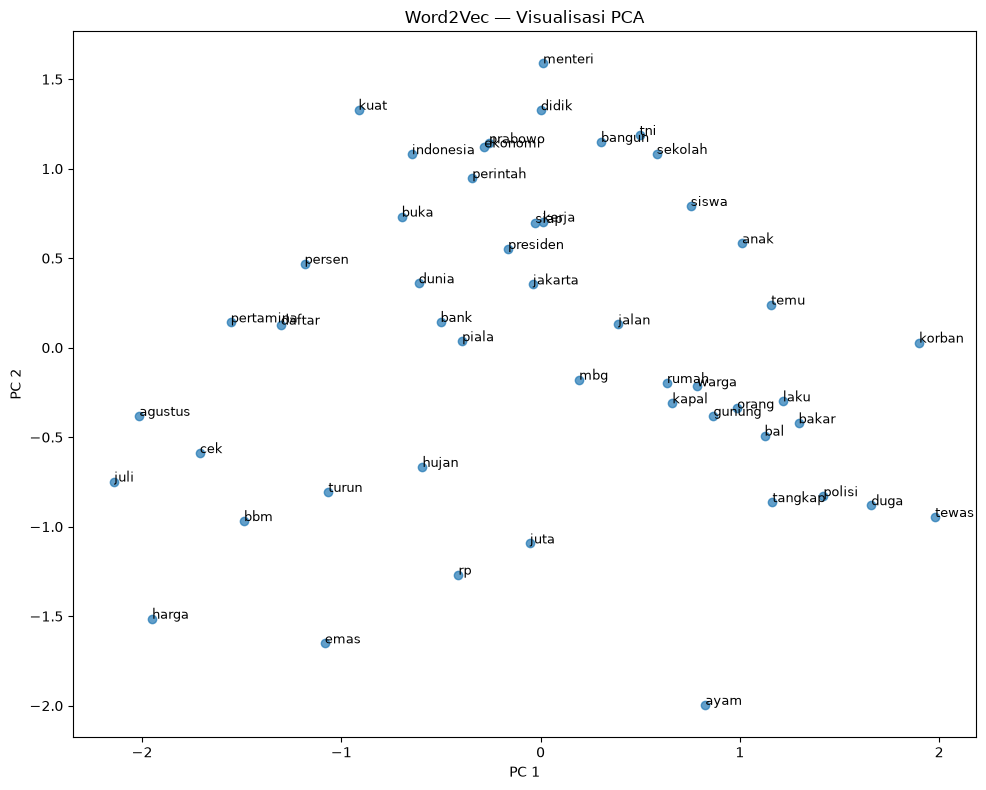

In [9]:
def visualize_embeddings_pca(words, model, title="Word Embedding PCA"):
    # Filter kata yang ada dalam vocabulary
    valid_words = [w for w in words if w in model.wv]
    if not valid_words:
        print("Tidak ada kata yang tersedia dalam vocabulary.")
        return

    vectors = np.array([model.wv[w] for w in valid_words])

    # Reduksi ke 2D dengan PCA
    pca = PCA(n_components=2)
    vectors_2d = pca.fit_transform(vectors)

    plt.figure(figsize=(10, 8))
    plt.scatter(vectors_2d[:, 0], vectors_2d[:, 1], alpha=0.7)
    for i, word in enumerate(valid_words):
        plt.annotate(
            word,
            xy=(vectors_2d[i, 0], vectors_2d[i, 1]),
            fontsize=9
        )
    plt.title(title)
    plt.xlabel("PC 1")
    plt.ylabel("PC 2")
    plt.tight_layout()
    plt.show()

# Ambil top 50 kata paling sering
top_words = [word for word, _ in model_w2v.wv.key_to_index.items()][:50]
visualize_embeddings_pca(top_words, model_w2v, "Word2Vec — Visualisasi PCA")

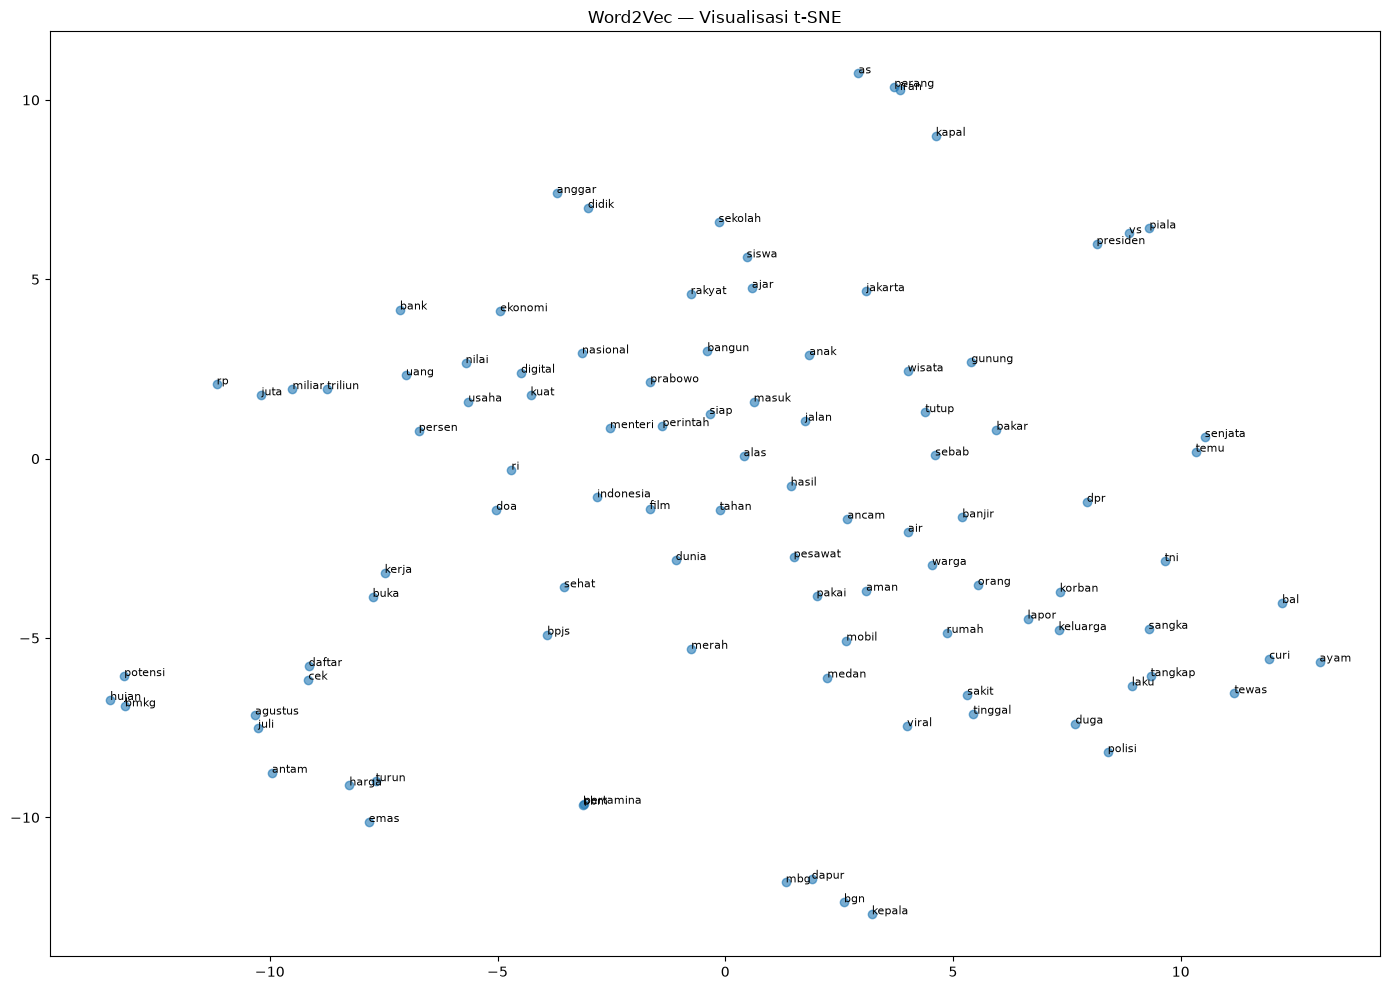

In [10]:
def visualize_embeddings_tsne(words, model, title="Word Embedding t-SNE"):
    valid_words = [w for w in words if w in model.wv]
    if len(valid_words) < 10:
        print("Terlalu sedikit kata untuk t-SNE.")
        return

    vectors = np.array([model.wv[w] for w in valid_words])

    tsne = TSNE(n_components=2, perplexity=15, random_state=42,
    n_iter_without_progress=1000)
    vectors_2d = tsne.fit_transform(vectors)

    plt.figure(figsize=(14, 10))
    plt.scatter(vectors_2d[:, 0], vectors_2d[:, 1], alpha=0.6)
    for i, word in enumerate(valid_words):
        plt.annotate(
            word,
            xy=(vectors_2d[i, 0], vectors_2d[i, 1]),
            fontsize=8
        )
    plt.title(title)
    plt.tight_layout()
    plt.show()

top_words = [word for word, _ in model_w2v.wv.key_to_index.items()][:100]
visualize_embeddings_tsne(top_words, model_w2v, "Word2Vec — Visualisasi t-SNE")

In [11]:
# Latih model FastText
model_ft = FastText(
    sentences=sentences,
    vector_size=100,
    window=5,
    min_count=2,
    workers=4,
    epochs=10
)

# FastText dapat menangani kata baru (OOV)
oov_word = "ketidakberhasilannya"  # kata yang mungkin tidak ada di corpus
vector_oov = model_ft.wv[oov_word]
print(f"FastText berhasil menghasilkan vektor untuk '{oov_word}'")
print(f"Dimensi: {vector_oov.shape}")

FastText berhasil menghasilkan vektor untuk 'ketidakberhasilannya'
Dimensi: (100,)


In [12]:
test_oov = "pemrogramannya"  # kata dengan imbuhan kompleks

print("Perbandingan Word2Vec vs FastText:")
print("-" * 50)

if test_oov in model_w2v.wv:
    w2v_similar = model_w2v.wv.most_similar(test_oov, topn=5)
    print(f"\nWord2Vec — '{test_oov}':")
    for w, s in w2v_similar:
        print(f"  {w:<20}: {s:.4f}")
else:
    print(f"\nWord2Vec: '{test_oov}' tidak ada dalam vocabulary (OOV)")

ft_similar = model_ft.wv.most_similar(test_oov, topn=5)
print(f"\nFastText — '{test_oov}':")
for w, s in ft_similar:
    print(f"  {w:<20}: {s:.4f}")

Perbandingan Word2Vec vs FastText:
--------------------------------------------------

Word2Vec: 'pemrogramannya' tidak ada dalam vocabulary (OOV)

FastText — 'pemrogramannya':
  strategi            : 0.9998
  diet                : 0.9998
  progo               : 0.9998
  pegawai             : 0.9998
  bima                : 0.9997
